# P1 Car Sales — Notebook 1: Exploratory Data Analysis
**Team:** DataStars &nbsp;|&nbsp; **Course:** MSDS 565 — Unit 1 Tabular Regression

Goal: understand the raw dataset's structure, distributions, and relationship with
`price` well enough that a stranger could pick up Notebook 2 from here. No
preprocessing or modeling happens in this notebook — only EDA and flagging
issues for later.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')

DATA_PATH = r"C:\Users\cto\Desktop\MSDS-565\First-Project\CarSales_Large.csv"
TARGET = "price"

df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 302,590  |  Columns: 66


,Unnamed: 0,city,back_legroom,bed,bed_height,bed_length,body_type,cabin,city_fuel_economy,combine_fuel_economy,daysonmarket,dealer_zip,description,engine_cylinders,engine_displacement,engine_type,exterior_color,fleet,frame_damaged,franchise_dealer,franchise_make,front_legroom,fuel_tank_volume,fuel_type,has_accidents,height,highway_fuel_economy,horsepower,interior_color,isCab,is_certified,is_cpo,is_new,is_oemcpo,latitude,length,listed_date,listing_color,listing_id,longitude,main_picture_url,major_options,make_name,maximum_seating,mileage,model_name,owner_count,power,price,salvage,savings_amount,seller_rating,sp_id,sp_name,theft_title,torque,transmission,transmission_display,trimId,trim_name,vehicle_damage_category,wheel_system,wheel_system_display,wheelbase,width,year
0,273335,Denver,NaN,NaN,NaN,NaN,Pickup Truck,NaN,NaN,NaN,66,80231,"Non-smoker owner, Vehicle Runs Well, Smooth ri...",V8,NaN,V8,Grey,False,False,False,NaN,NaN,NaN,Gasoline,False,NaN,NaN,NaN,Black,False,NaN,NaN,False,NaN,39.6802,NaN,2020-07-08,GRAY,275999568,-104.9030,https://static.cargurus.com/images/forsale/202...,['Steel Wheels'],Toyota,NaN,194490.0,Tundra,3.0,NaN,13900.0,False,766,4.571429,435171.0,King Auto,False,NaN,A,6-Speed Automatic Overdrive,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2008
1,20660,Houston,34.4 in,NaN,NaN,NaN,SUV / Crossover,NaN,12.0,NaN,117,77074,We are excited to offer this 2020 Lexus LX. Th...,V8,5700.0,V8,Nebula Gray Pearl,NaN,NaN,True,Lexus,42.9 in,24.6 gal,Gasoline,NaN,75.2 in,16.0,383.0,NaN,NaN,NaN,NaN,True,NaN,29.6673,200 in,2020-05-17,GRAY,272176442,-95.5518,https://static.cargurus.com/images/forsale/202...,"['Leather Seats', 'Sunroof/Moonroof', 'Navigat...",Lexus,8 seats,98.0,LX,NaN,"383 hp @ 5,600 RPM",98390.0,NaN,0,4.035088,239576.0,Sterling McCall Lexus,NaN,"403 lb-ft @ 3,600 RPM",A,Automatic,t91117,570 3-Row 4WD,NaN,AWD,All-Wheel Drive,112.2 in,78 in,2020
2,129041,Las Vegas,37.9 in,NaN,NaN,NaN,Sedan,NaN,23.0,NaN,66,89146,"WHEELS, 18"" (45.7 CM) PREMIUM PAINTED ALLOY WI...",I4,2000.0,I4,Wave Metallic,NaN,NaN,True,Cadillac,42.4 in,17.4 gal,Gasoline,NaN,57.2 in,32.0,237.0,Jet Black with Jet Black Accents,NaN,NaN,NaN,True,NaN,36.1443,193.8 in,2020-07-07,UNKNOWN,275926401,-115.2100,https://static.cargurus.com/images/forsale/202...,"['Leather Seats', 'Sunroof/Moonroof', 'Alloy W...",Cadillac,5 seats,14.0,CT5,NaN,"335 hp @ 5,600 RPM",43960.0,NaN,0,4.387097,50957.0,Cadillac of Las Vegas,NaN,"405 lb-ft @ 2,400 RPM",A,Automatic,t86856,Premium Luxury Sedan RWD,NaN,RWD,Rear-Wheel Drive,116 in,80.3 in,2020
3,246910,Cincinnati,38.5 in,NaN,NaN,NaN,SUV / Crossover,NaN,17.0,NaN,73,45255,"CARFAX One-Owner. 18"" Alloy Wheels, 3rd row se...",V6,3500.0,V6,Gray,False,False,True,Subaru,41.4 in,21 gal,Gasoline,False,72.7 in,24.0,250.0,Brown (Beige),False,NaN,NaN,False,NaN,39.0729,191.4 in,2020-06-30,GRAY,275327492,-84.3332,https://static.cargurus.com/images/forsale/202...,"['Leather Seats', 'Sunroof/Moonroof', 'Alloy W...",Honda,8 seats,196315.0,Pilot,1.0,"250 hp @ 5,700 RPM",7695.0,False,109,4.552632,283867.0,Beechmont Subaru,False,"253 lb-ft @ 4,800 RPM",A,5-Speed Automatic,t46998,EX 4WD,NaN,4WD,Four-Wheel Drive,109.2 in,78.5 in,2013
4,266975,Tucson,36.9 in,NaN,NaN,NaN,SUV / Crossover,NaN,20.0,NaN,35,85712,Whether you NEED an SUV for your family and th...,I4,2400.0,I4,Silver Topaz Metallic,True,False,False,NaN,40.7 in,19 gal,Gasoline,False,67 in,28.0,180.0,Black,True,NaN,NaN,False,NaN,32.2365,180.1 in,2020-08-07,SILVER,278674980,-110.8630,NaN,"['Navigation System', 'Alloy Wheels', 'Bluetoo...",Chevrolet,5 seats,91212.0,Captiva Sport,4.0,"180 hp @ 6,700 RPM",9479.0,False,675,4.000000,312337.0,Chapman Used Cars on Speedway,False,"172 lb-ft @ 4,900 RPM",A,6-Speed Automatic,t49723,2LS,NaN,FWD,Front-Wheel Drive,106.6 in,72.8 in,2013


## 1. Structure

### 1.1 Shape and dtypes

In [2]:
df.dtypes.value_counts()

object     44
float64    14
int64       6
bool        2
Name: count, dtype: int64

In [3]:
df.dtypes.sort_values().to_frame("dtype")

,dtype
is_new,bool
franchise_dealer,bool
savings_amount,int64
listing_id,int64
dealer_zip,int64
...,...
is_oemcpo,object
length,object
body_type,object
fuel_tank_volume,object


**Interpretation:** _Note the row/column count and how many columns fall into
each dtype above. Flag anything surprising here (e.g. a numeric-looking column
stored as `object`) — that's a preprocessing candidate for Notebook 2._


### 1.2 Missing values

In [4]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.concat([missing, missing_pct], axis=1, keys=["missing_count", "missing_pct"])
missing_summary = missing_summary[missing_summary["missing_count"] > 0]
missing_summary

,missing_count,missing_pct
vehicle_damage_category,302590,100.00
combine_fuel_economy,302590,100.00
is_certified,302590,100.00
bed,300273,99.23
cabin,297035,98.16
is_oemcpo,291404,96.30
is_cpo,286809,94.78
bed_height,264711,87.48
bed_length,264711,87.48
owner_count,147889,48.87


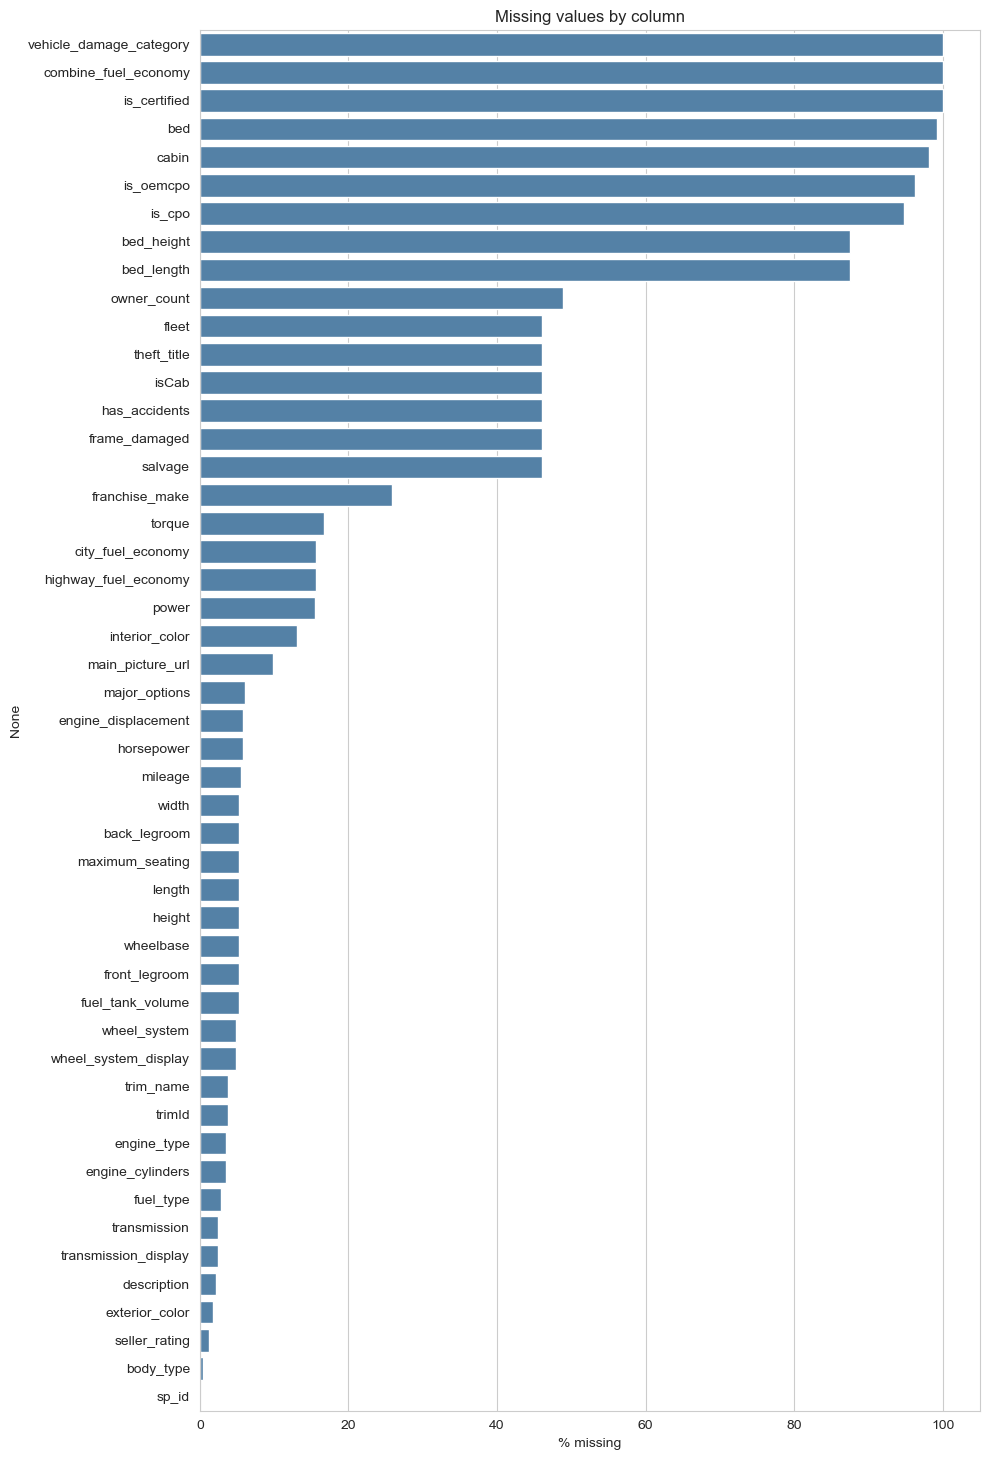

In [5]:
if len(missing_summary) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(missing_summary) * 0.3)))
    sns.barplot(x=missing_summary["missing_pct"], y=missing_summary.index, ax=ax, color="steelblue")
    ax.set_xlabel("% missing")
    ax.set_title("Missing values by column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

**Interpretation:** _Call out which columns are missing enough data to need a
real imputation strategy in Notebook 2, versus which are trivial. Flag any
column missing more than ~50% as a drop candidate._


### 1.3 Columns likely useless for predicting price

In [6]:
n = len(df)
candidate_flags = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "unique_ratio": (df.nunique() / n).round(3),
    "missing_pct": missing_pct.reindex(df.columns).fillna(0),
})
candidate_flags["constant"] = df.nunique() <= 1
candidate_flags["likely_id_or_free_text"] = candidate_flags["unique_ratio"] > 0.9
candidate_flags.sort_values("unique_ratio", ascending=False)


,dtype,n_unique,unique_ratio,missing_pct,constant,likely_id_or_free_text
Unnamed: 0,int64,302590,1.000,0.00,False,True
listing_id,int64,302587,1.000,0.00,False,True
description,object,260806,0.862,2.21,False,False
main_picture_url,object,254865,0.842,9.89,False,False
mileage,float64,91951,0.304,5.61,False,False
...,...,...,...,...,...,...
isCab,object,2,0.000,46.10,False,False
is_certified,float64,0,0.000,100.00,True,False
is_cpo,object,1,0.000,94.78,True,False
is_new,bool,2,0.000,0.00,False,False


**Interpretation:** _Columns with `unique_ratio` near 1.0 are typically IDs,
VINs, URLs, or free-text descriptions — they carry no generalizable signal for
price and are drop candidates. Constant columns (`n_unique` ≤ 1) carry zero
information. List the specific columns you're flagging so Notebook 2 can act
on them._


### 1.4 Data quality issues

In [7]:
print(f"Fully duplicated rows: {df.duplicated().sum():,}")


Fully duplicated rows: 0


In [8]:
# Peek at a few values from every text column to spot malformed strings,
# inconsistent casing, embedded units/symbols, etc.
obj_cols = df.select_dtypes(include="object").columns
for col in obj_cols:
    sample_vals = df[col].dropna().unique()[:5]
    print(f"{col:30s} -> {list(sample_vals)}")


city                           -> ['Denver', 'Houston', 'Las Vegas', 'Cincinnati', 'Tucson']
back_legroom                   -> ['34.4 in', '37.9 in', '38.5 in', '36.9 in', '39.5 in']
bed                            -> ['Short', 'Regular', 'Long']
bed_height                     -> ['--']
bed_length                     -> ['78.9 in', '67.1 in', '67.4 in', '78.8 in', '69.3 in']
body_type                      -> ['Pickup Truck', 'SUV / Crossover', 'Sedan', 'Hatchback', 'Wagon']
cabin                          -> ['Large Crew Cab', 'Crew Cab', 'Extended Cab', 'Regular Cab']
description                    -> ['Non-smoker owner, Vehicle Runs Well, Smooth ride, New tires, Regularly maintained, Lots of storage, Arctic cold a/c, Must test drive, Mint Condition, Great first ride[!@@Additional Info@@!]V8 5.7 Liter,Automatic 6-Spd w/Overdrive,4WD,Traction Control,Stability Control,ABS (4-Wheel),Anti-Theft System,Keyless Entry,Air Conditioning,Power Windows,Power Door Locks,Cruise Control,Power Steeri

In [9]:
# Check numeric columns for values that shouldn't be possible
numeric_cols = df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    neg = (df[col] < 0).sum()
    if neg > 0:
        print(f"{col}: {neg} negative values")

if "year" in df.columns:
    print("\nYear range:", df["year"].min(), "-", df["year"].max())
if TARGET in df.columns:
    print(f"{TARGET} <= 0 count:", (df[TARGET] <= 0).sum())


longitude: 302590 negative values

Year range: 1923 - 2021
price <= 0 count: 0


**Interpretation:** _Document every issue you find here in plain language —
e.g. "`X` stores numbers as text with a `$` prefix," "`year` has values before
1900," "`price` has zero/negative entries," "`make` has inconsistent
capitalization." Each one becomes a to-do for Notebook 2's preprocessing._


## 2. Univariate distributions

### 2.1 Numeric columns

In [10]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,302590.0,2.022231e+05,1.167320e+05,0.000000e+00,1.011032e+05,2.021710e+05,3.033765e+05,4.043580e+05
city_fuel_economy,255261.0,2.289297e+01,8.888540e+00,8.000000e+00,1.800000e+01,2.200000e+01,2.600000e+01,1.270000e+02
combine_fuel_economy,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
daysonmarket,302590.0,7.218987e+01,1.058132e+02,0.000000e+00,1.400000e+01,3.400000e+01,7.700000e+01,2.416000e+03
dealer_zip,302590.0,6.056536e+04,2.289790e+04,1.104000e+03,3.361900e+04,7.314100e+04,7.872900e+04,9.747700e+04
engine_displacement,285071.0,2.932351e+03,1.322871e+03,7.000000e+02,2.000000e+03,2.500000e+03,3.600000e+03,8.400000e+03
highway_fuel_economy,255261.0,2.980181e+01,7.906289e+00,1.100000e+01,2.500000e+01,2.900000e+01,3.400000e+01,1.270000e+02
horsepower,285071.0,2.456699e+02,9.097910e+01,6.700000e+01,1.720000e+02,2.410000e+02,3.000000e+02,1.001000e+03
is_certified,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,302590.0,3.376099e+01,4.475665e+00,2.559610e+01,2.976700e+01,3.350830e+01,3.732800e+01,4.563740e+01


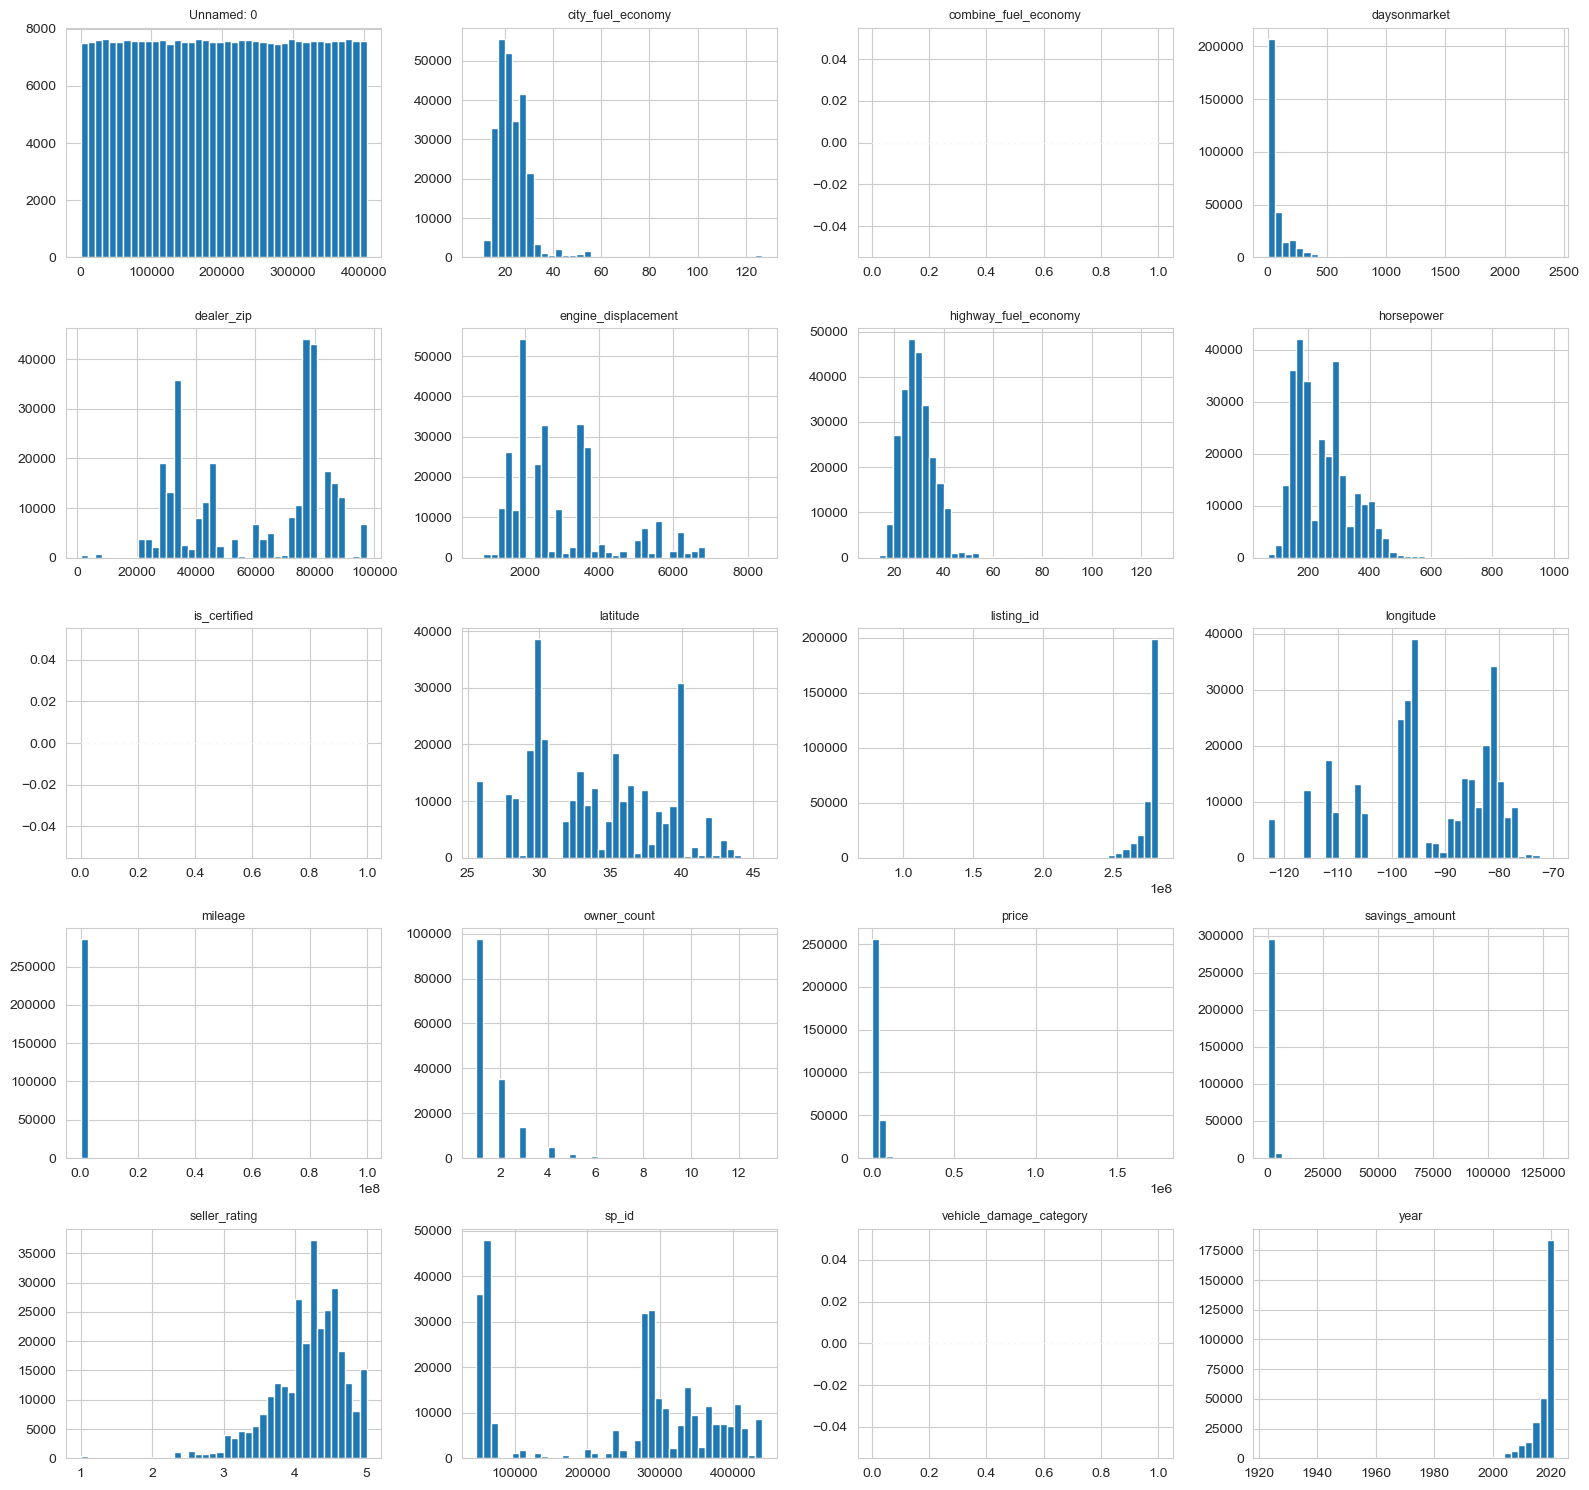

In [11]:
n_num = len(numeric_cols)
n_cols_grid = 4
n_rows_grid = int(np.ceil(n_num / n_cols_grid))
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(4 * n_cols_grid, 3 * n_rows_grid))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    df[col].dropna().hist(bins=40, ax=axes[i])
    axes[i].set_title(col, fontsize=9)
for j in range(i + 1, len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()


In [12]:
def iqr_outlier_pct(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).mean() * 100

outlier_pct = df[numeric_cols].apply(lambda s: iqr_outlier_pct(s.dropna()))
outlier_pct.sort_values(ascending=False).to_frame("pct_outliers_iqr")


,pct_outliers_iqr
daysonmarket,13.803827
listing_id,10.505304
year,9.881688
mileage,7.826242
savings_amount,7.801315
owner_count,5.317354
engine_displacement,4.265604
price,3.312403
seller_rating,3.196445
city_fuel_economy,2.978912


**Interpretation:** _Which numeric columns have the highest outlier percentage
above? For `price`, `mileage`, and `year` specifically — do the outliers look
like genuine rare cars/high-mileage vehicles, or data-entry errors (e.g. a
`year` of 2099)? This determines how Notebook 2 should treat them (cap, drop,
or leave alone)._


### 2.2 Categorical columns

In [13]:
cat_cols = df.select_dtypes(include="object").columns
cardinality = df[cat_cols].nunique().sort_values(ascending=False)
cardinality.to_frame("n_unique")


,n_unique
description,260806
main_picture_url,254865
major_options,50632
trimId,23808
interior_color,9731
exterior_color,7604
trim_name,5713
sp_name,3239
power,1631
torque,1601


In [14]:
HIGH_CARD_THRESHOLD = 20
high_card_cols = cardinality[cardinality > HIGH_CARD_THRESHOLD].index.tolist()
low_card_cols = cardinality[cardinality <= HIGH_CARD_THRESHOLD].index.tolist()

print("High-cardinality columns (> {} unique values):".format(HIGH_CARD_THRESHOLD))
print(high_card_cols)
print("\nLow/medium-cardinality columns:")
print(low_card_cols)


High-cardinality columns (> 20 unique values):
['description', 'main_picture_url', 'major_options', 'trimId', 'interior_color', 'exterior_color', 'trim_name', 'sp_name', 'power', 'torque', 'model_name', 'listed_date', 'length', 'height', 'wheelbase', 'width', 'back_legroom', 'fuel_tank_volume', 'front_legroom', 'bed_length', 'make_name', 'franchise_make', 'transmission_display', 'engine_type', 'engine_cylinders', 'city']

Low/medium-cardinality columns:
['listing_color', 'maximum_seating', 'body_type', 'fuel_type', 'wheel_system_display', 'wheel_system', 'transmission', 'cabin', 'bed', 'fleet', 'theft_title', 'frame_damaged', 'salvage', 'has_accidents', 'isCab', 'is_cpo', 'bed_height', 'is_oemcpo']


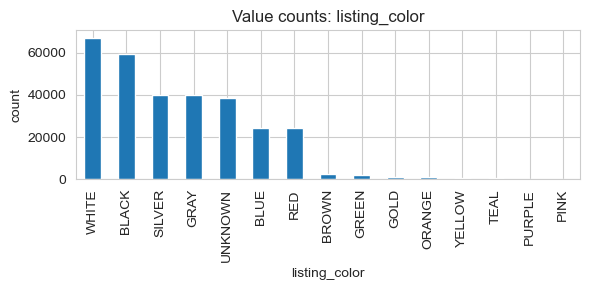

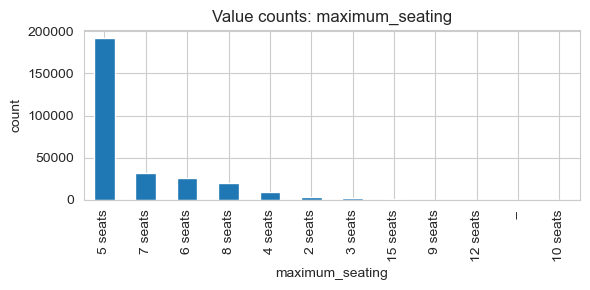

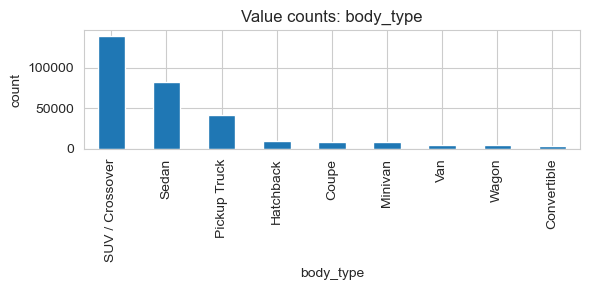

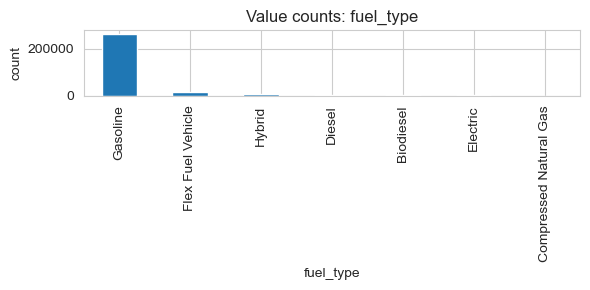

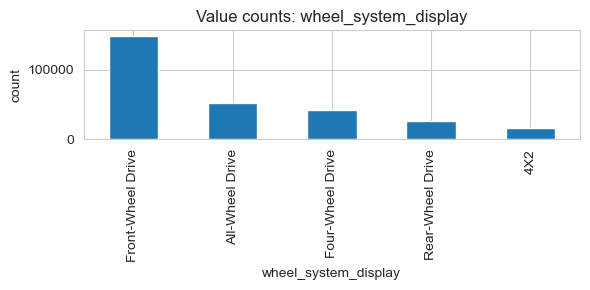

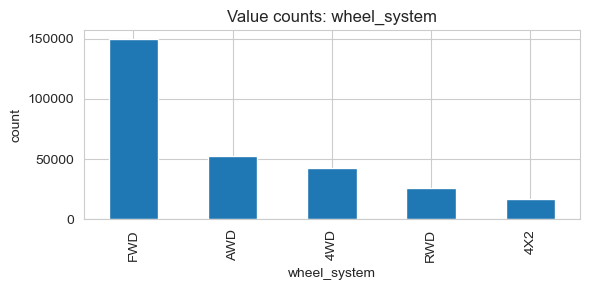

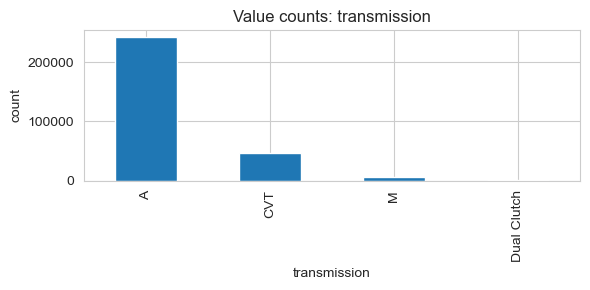

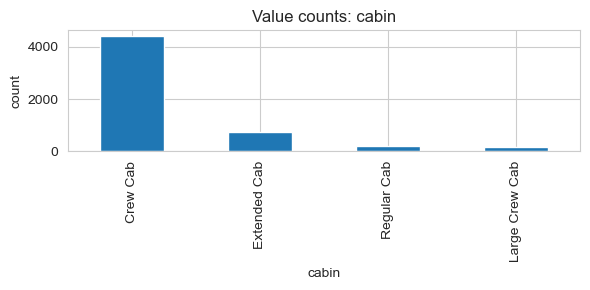

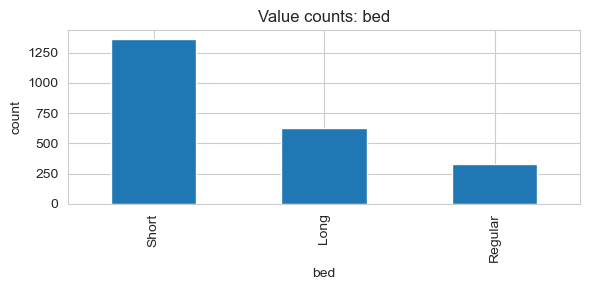

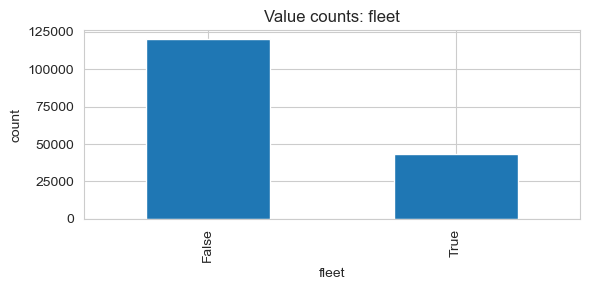

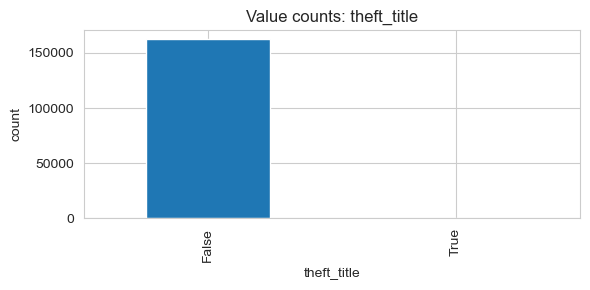

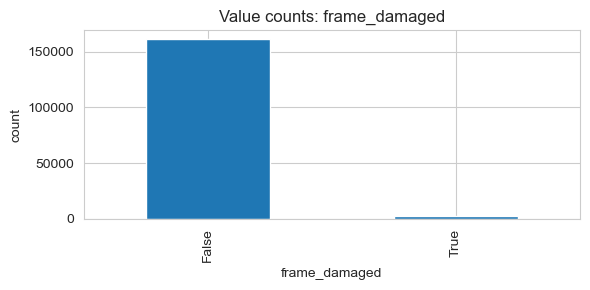

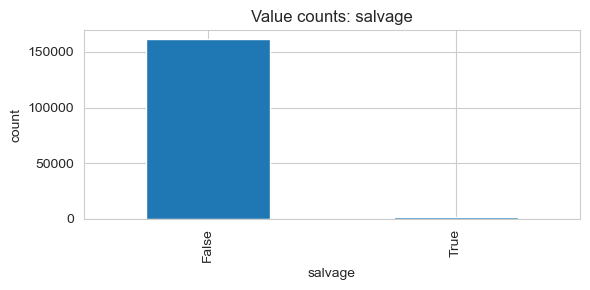

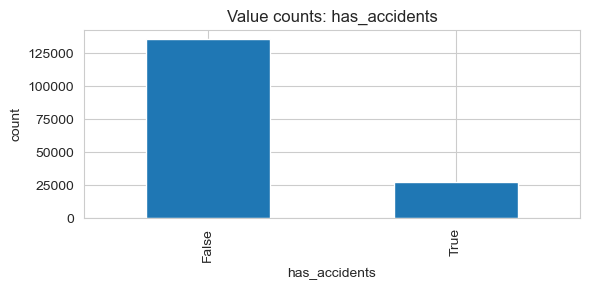

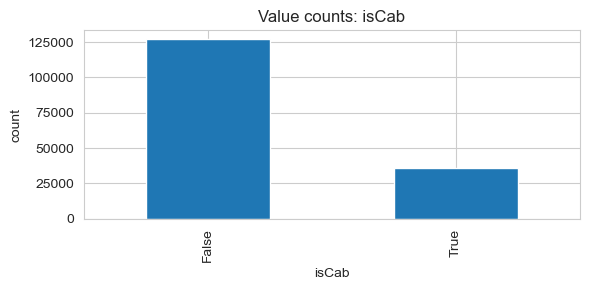

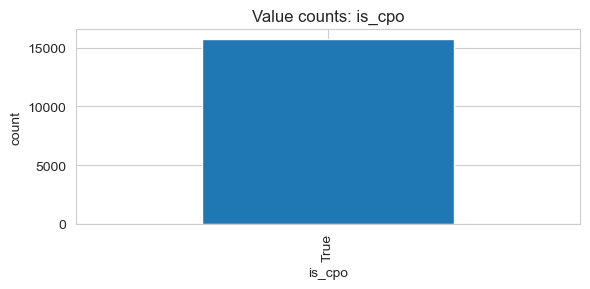

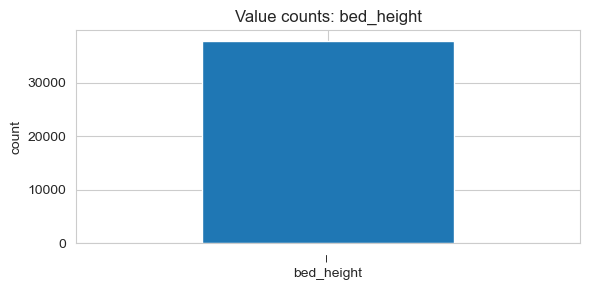

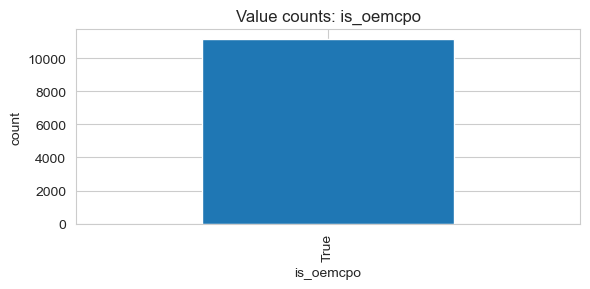

In [15]:
for col in low_card_cols:
    plt.figure(figsize=(6, 3))
    df[col].value_counts().head(15).plot(kind="bar")
    plt.title(f"Value counts: {col}")
    plt.ylabel("count")
    plt.tight_layout()
    plt.show()


**Interpretation:** _Note which columns are high-cardinality — those will need
special handling in Notebook 2's one-hot encoding (top-20 + drop-reference
rule). Also flag any low-cardinality column that's dominated by a single
category (near-constant → low predictive value)._


## 3. Bivariate relationships

### 3.1 What correlates with price?

In [16]:
corr_with_target = df[numeric_cols].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr_with_target.to_frame("corr_with_price")


,corr_with_price
horsepower,0.605429
engine_displacement,0.362183
year,0.358032
highway_fuel_economy,-0.243255
owner_count,-0.212874
city_fuel_economy,-0.169005
sp_id,-0.148704
mileage,-0.105582
seller_rating,0.089174
daysonmarket,0.050504


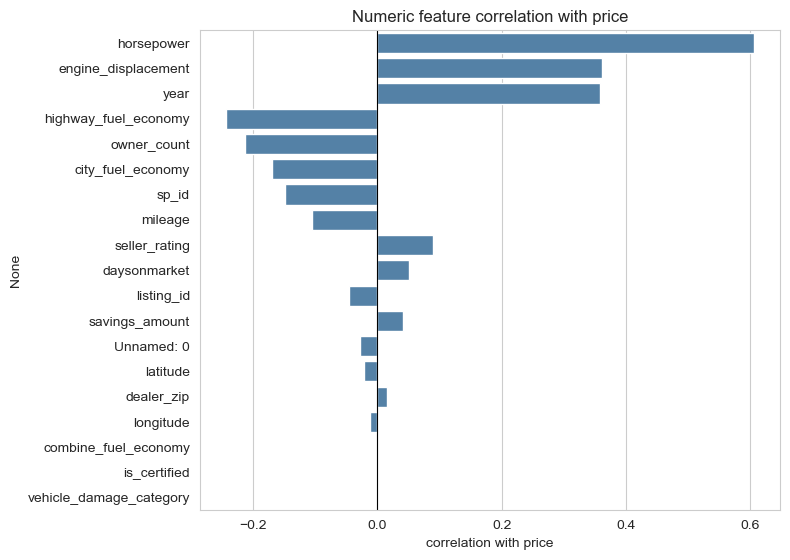

In [17]:
plt.figure(figsize=(8, max(4, len(corr_with_target) * 0.3)))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("correlation with price")
plt.title("Numeric feature correlation with price")
plt.tight_layout()
plt.show()


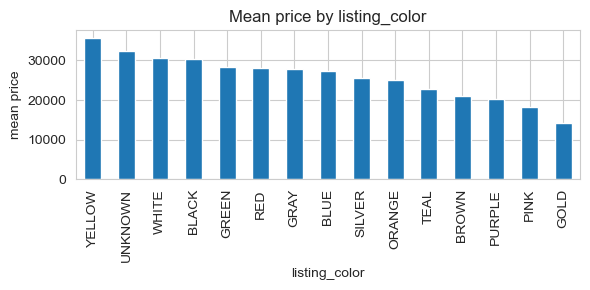

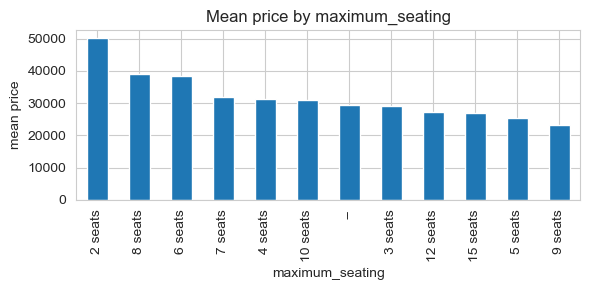

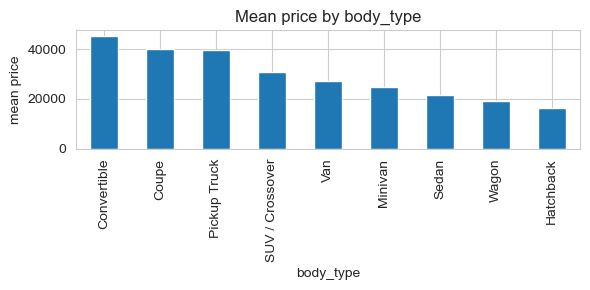

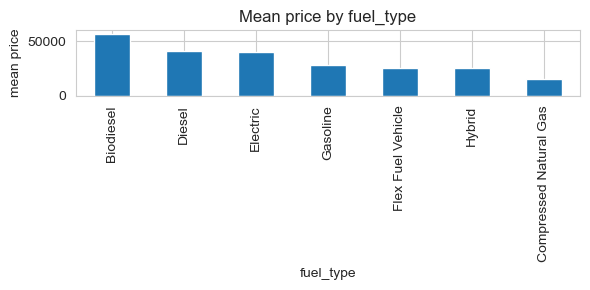

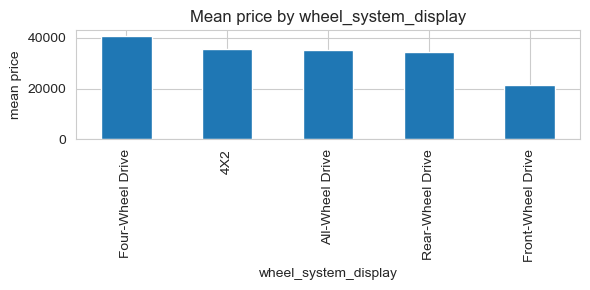

In [18]:
# Mean price by category, for a handful of low-cardinality categorical columns
for col in low_card_cols[:5]:
    means = df.groupby(col)[TARGET].mean().sort_values(ascending=False)
    plt.figure(figsize=(6, 3))
    means.head(15).plot(kind="bar")
    plt.title(f"Mean {TARGET} by {col}")
    plt.ylabel(f"mean {TARGET}")
    plt.tight_layout()
    plt.show()


**Interpretation:** _Which numeric features have the strongest (positive or
negative) relationship with `price`? Do the categorical group-means above show
meaningful price separation between categories, or mostly noise?_


### 3.2 Are the top predictors correlated with each other?

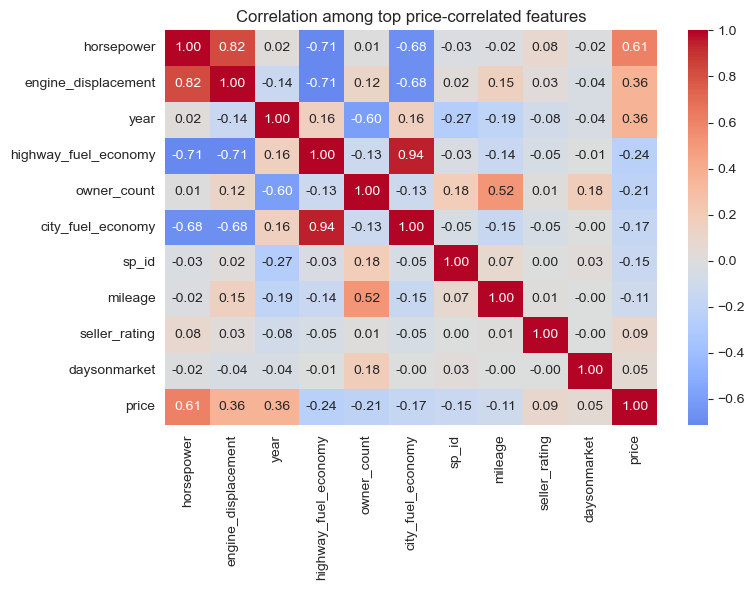

In [19]:
top_features = corr_with_target.abs().sort_values(ascending=False).head(10).index.tolist()
plt.figure(figsize=(8, 6))
sns.heatmap(df[top_features + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation among top price-correlated features")
plt.tight_layout()
plt.show()


**Interpretation:** _Flag any pair of features here with |correlation| > ~0.8
— that's a multicollinearity signal worth remembering when you get to
Notebook 4's VIF filtering._


## Summary of flags for Notebook 2

_Fill in as a bullet list once the cells above have run on the real data:_
- **Drop candidates:**
- **Dtype fixes needed:**
- **Outlier columns needing special handling:**
- **Imputation targets and suggested strategy:**
- **High-cardinality columns:**
